# Rubin footprint with a joint stellar-density and E(B-V) cut (rubin_sim MAF)

This notebook evaluates `maf.StarDensityMetric` on a full-sky `HealpixSlicer`, overlays E(B-V) contours from `maf.DustMap`, shades the region that passes a joint cut on both, and outlines the Rubin baseline survey footprint and its Wide Fast Deep (WFD) area. Section 10 then builds a modified footprint. The joint cut replaces `lowdust`. A smoothed Galactic-plane region (`rgps`), shaped by the TVS SC proposal, replaces `bulgy`. An ecliptic bridge joins the two. The section reports areas, pointings and visits, and exports HEALPix maps.

- **Footprint:** `rubin_scheduler.scheduler.utils.get_current_footprint`. This is the scheduler's own region map behind the [baseline WFD](https://survey-strategy.lsst.io/baseline/wfd.html) (about 19.6k deg²). WFD is taken as the same set of regions that MAF's `make_wfd_subset_slicer` uses.

- **Stellar density:** `maf.TrilegalDensityMap` (TRILEGAL, includes the bulge) or `maf.StellarDensityMap` (CatSim/GalFast; disk and halo only, **no bulge**).
- **Dust:** `maf.DustMap` (SFD E(B-V)).

Neither map depends on visits, so no OpSim database is needed. The maps are loaded straight onto the slicer's slice points.

## 1. Environment check

Checks that `rubin_sim` imports and that the map files are where MAF looks for them (`$RUBIN_SIM_DATA_DIR`, or `~/rubin_sim_data` if that isn't set).

If the maps are missing, either point `RUBIN_SIM_DATA_DIR` at an existing copy, or run this in a terminal and then restart the kernel:

```bash
pip install --user rubin-sim
rs_download_data --dirs maps
scheduler_download_data      # footprint inputs: scheduler/dust_maps, Euclid contour
```

In [1]:
import os
# os.environ["RUBIN_SIM_DATA_DIR"] = "/path/to/rubin_sim_data"   # uncomment to override

import rubin_sim
from rubin_scheduler.data import get_data_dir

print("rubin_sim", rubin_sim.__version__)
data_dir = get_data_dir()
print("data dir:", data_dir)
for sub in ["maps/TriMaps", "maps/StarMaps", "maps/DustMaps", "scheduler/dust_maps"]:
    p = os.path.join(data_dir, sub)
    print(f"  {sub:20s}", "OK" if os.path.isdir(p) else "MISSING")

rubin_sim 2.6.2
data dir: /home/kolsen/rubin_sim_data
  maps/TriMaps         OK
  maps/StarMaps        OK
  maps/DustMaps        OK
  scheduler/dust_maps  OK


In [2]:
import json
import os
import urllib.request
import warnings

import astropy.units as u
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rubin_sim.maf as maf
from astropy.coordinates import SkyCoord
from astropy.io import fits
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from rubin_scheduler.scheduler.utils import get_current_footprint
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

%matplotlib inline

## 2. Settings

All the control parameters are in this cell; the cells below only compute and plot.

In [3]:
# ============================== maps and joint cut ==============================
NSIDE = 64                   # native nside of the star-density maps
FILTER = "r"                 # u g r i z y
STAR_MODEL = "trilegal"      # "trilegal" (has bulge) or "galfast" (no bulge)
MAG_LIMIT = 17.0             # count stars brighter than this (valid ~15-28)
STARDENS_CUT = 0.0002        # stars / arcsec^2 (same units as the metric)
STARDENS_SIDE = "below"      # keep pixels "above" or "below" STARDENS_CUT
EBV_CUT = 0.12               # E(B-V) in mag
EBV_SIDE = "below"           # keep pixels "above" or "below" EBV_CUT

# ============================== current Rubin footprint ==============================
# WFD = the regions MAF's make_wfd_subset_slicer uses
WFD_LABELS = ["lowdust", "euclid_overlap", "virgo", "bulgy", "LMC_SMC"]
RESTRICT_CUT_TO_WFD = True   # section 7: joint cut counts only pixels inside the WFD

# ============================== modified footprint: lowdust ==============================
CLAIM_FROM_LABELS = []       # other regions the cut may convert to lowdust
LOWDUST_SMOOTH_FWHM = 5.0    # smooth the lowdust edge (deg); 0 = off
HOLE_FILL_LABELS = ["dusty_plane", "nes", "scp"]   # non-WFD regions that absorb removed area
HOLE_MODE = "component"      # lowdust holes: "component" (whole hole -> one region) or "pixel"

# ============================== modified footprint: Galactic plane (rgps) ==============================
# The rgps region follows the TVS SC proposed region (section 9), with the thin northern
# plane removed, then its border trimmed (optional), smoothed and cleaned of islands.
RGPS_LABEL = "rgps"
RGPS_TARGET_AREA = 1700.0    # deg^2 budget for rgps; any shortfall is added to the bridge
RGPS_NORTH_L_MIN = 30.0      # drop rgps at l > this (deg): beyond ~30 deg the TVS region is a thin |b| < 3 deg strip
RGPS_PROTECT = ["lowdust", "LMC_SMC", "euclid_overlap", "virgo"]   # rgps never takes these
RGPS_EDGE_TRIM_FRAC = 0.0    # peel this fraction of rgps area off its border (-> dusty_plane); 0 = off
RGPS_EDGE_TRIM_TO_AREA = None  # or peel the border until rgps is this area (deg^2); overrides the fraction
RGPS_SMOOTH_FWHM = 4.0       # border smoothing (deg), also used for the edge trim; 0 = off
RGPS_MIN_NEIGHBOURS = 3      # cleanup: drop rgps pixels with fewer rgps neighbours (of 8); fill notches
# Roman RGPS wide-field boxes (Galactic l, b in deg; l in [-180, 180]), 691.15 deg^2, from
# roman-docs.stsci.edu/roman-community-defined-surveys/galactic-plane-survey
RGPS_BOXES = {
    "disk":            ((-67.0, 50.1), (-2.0, 2.0)),
    "carina_ext":      ((-79.0, -67.0), (-2.5, 2.0)),
    "bulge_bar_north": ((-10.0, 10.0), (2.0, 6.0)),
    "bulge_bar_south": ((-10.0, 10.0), (-6.0, -2.0)),
    "serpens_south":   ((26.5, 30.0), (2.0, 4.5)),
}
# TVS SC region recipe (LSST-TVSSC/software_tools, GalPlaneSurvey/modified_galplane_footprint.ipynb)
TVS_PRIORITY_URL = ("https://raw.githubusercontent.com/LSST-TVSSC/software_tools/main/"
                    "footprint_maps/priority_GalPlane_footprint_map_data_sum.fits")
TVS_REDUCE_FRACTION = 0.10   # keep highest-priority bulgy pixels down to (1 - this) of baseline visits
TVS_NVISITS_SOURCE = "opsim" # "opsim" (MAF count on the baseline run) or "uniform"
TVS_OPSIM_DB = None          # path to baseline_v5.3.0_10yrs.db; None = rubin_sim get_baseline()
TVS_B_MAX = 11.0             # keep b < this (deg)
TVS_DROP_L = (180.0, 270.0)  # drop pixels with l in this range (deg, 0-360)
TVS_BRIDGE_ELON = (235.0, 305.0)   # TVS ecliptic bridge, barycentric mean ecliptic (deg)
TVS_BRIDGE_ELAT = (-2.5, 2.5)

# ============================== modified footprint: ecliptic bridge ==============================
# A band along the ecliptic joining rgps to lowdust on both sides of the plane. It always
# includes the TVS ecliptic-bridge pixels; its width is solved to reach the target area.
BRIDGE_LABEL = "bridge"
BRIDGE_TARGET_AREA = 400.0   # deg^2, plus any rgps shortfall from RGPS_TARGET_AREA
BRIDGE_MAX_WIDTH = 30.0      # never wider than this (deg), so the band hugs the ecliptic
BRIDGE_ELAT_OFFSET = 0.0     # centre the band at this ecliptic latitude (deg)
BRIDGE_TAKE_FROM = ["dusty_plane"]   # only these regions become bridge
BRIDGE_NORTH_PLANE_B = 6.0   # bridge never takes l > RGPS_NORTH_L_MIN, |b| < this (deg)

# ============================== areas and visits ==============================
POINTINGS_PER_DEG2 = 1.3 / 9.6
# Visit budget: set a total to have section 10 solve STARDENS_CUT for it (keeping
# RGPS_EDGE_TRIM_FRAC and BRIDGE_TARGET_AREA as set above). None = use STARDENS_CUT as given.
TARGET_TOTAL_VISITS = None   # e.g. 1.8e6
STARDENS_SOLVE_MIN = 2e-5    # lowest STARDENS_CUT the solver may use (stars/arcsec^2)
STARDENS_SOLVE_ITER = 12     # bisection steps (each rebuilds the footprint, a few seconds)
WFD_VISITS = 750
VISITS = {                   # median visits per pointing, by region
    "lowdust": WFD_VISITS, "bulgy": WFD_VISITS, "LMC_SMC": WFD_VISITS,
    "euclid_overlap": WFD_VISITS, "virgo": WFD_VISITS,
    RGPS_LABEL: WFD_VISITS, BRIDGE_LABEL: WFD_VISITS,
    "dusty_plane": 170, "nes": 150, "scp": 100,
}

# ============================== plots ==============================
COORD = "C"                  # "C" equatorial; ["C", "G"] Galactic
EBV_LEVELS = [0.12]          # E(B-V) contour levels (section 8)
SHOW_FULL_FOOTPRINT = True   # section 8: also outline the whole survey footprint (dashed)
CUT_COLOR = "#ff3b8b"
WFD_COLOR = "#ff9f1c"
RGPS_CORE_COLOR = "#222222"  # Roman wide-field outline
ECLIPTIC_LATS = [0.0]        # e.g. [-10.0, 0.0, 10.0] to show the NES band
ECLIPTIC_COLOR = "#ffd23f"
SHOW_DECAPS = True
DECAPS_SOURCE = "moc"        # "moc" (CDS coverage map, falls back to box) or "box"
DECAPS_MOC_URL = "https://alasky.cds.unistra.fr/DECaPS/DR2/CDS_P_DECaPS_DR2_g/Moc.fits"
DECAPS_BOX = ((-124.0, 6.0), (-10.0, 10.0))   # (l range), (b range) deg; Saydjari et al. 2023
DECAPS_COLOR = "#00b4d8"

# ============================== outputs ==============================
OUTFILE = f"stardens_{STAR_MODEL}_{FILTER}{MAG_LIMIT:g}_ebv.png"          # section 8 map
TABLE_STEM = f"footprint_GPmod_{STAR_MODEL}_{FILTER}{MAG_LIMIT:g}"       # areas / visits CSVs, map PNG
OUT_NSIDE = 64               # exported HEALPix maps: 64 = working resolution; 32 = rubin_scheduler default
OUT_STEM = f"footprint_GPmod_nside{OUT_NSIDE}"
BANDS = ["u", "g", "r", "i", "z", "y"]
BORROW_RATIOS = {RGPS_LABEL: "bulgy", BRIDGE_LABEL: "lowdust"}   # band ratios for the new regions

## 3. Load the maps onto the slice points

In [4]:
slicer = maf.HealpixSlicer(nside=NSIDE, verbose=False)
sp = dict(slicer.slice_points)  # ra, dec (rad), sid, nside, gall, galb

if STAR_MODEL == "trilegal":
    maf.TrilegalDensityMap(filtername=FILTER, nside=NSIDE).run(sp)
else:
    maf.StellarDensityMap(filtername=FILTER).run(sp)
maf.DustMap(nside=NSIDE).run(sp)

print(sorted(k for k in sp if k.startswith(("star", "ebv"))))

['ebv', 'starLumFunc_r', 'starMapBins_r']


## 4. Evaluate `StarDensityMetric` at each pixel

This gives stars per square arcsecond brighter than `MAG_LIMIT`.

In [5]:
metric = maf.StarDensityMetric(filtername=FILTER, mag_limit=MAG_LIMIT)
lf_key, bin_key = f"starLumFunc_{FILTER}", f"starMapBins_{FILTER}"
stardens = np.full(hp.nside2npix(NSIDE), hp.UNSEEN)
for i in range(stardens.size):
    val = metric.run(None, slice_point={lf_key: sp[lf_key][i], bin_key: sp[bin_key]})
    if val != metric.badval and val > 0:
        stardens[i] = val

ebv = np.asarray(sp["ebv"], dtype=float)
logdens = np.where(stardens > 0, np.log10(stardens), hp.UNSEEN)
print(f"valid pixels: {(stardens > 0).sum()} / {stardens.size}")

valid pixels: 40375 / 49152


## 5. Check coordinate frames and rotate

MAF assumes both maps are stored in equatorial coordinates. This cell checks that from the data: stars and dust both pile up at low |b|, so it tests whether the brightest 5% of pixels sit closer to the Galactic plane when the map is read as equatorial (C) or as Galactic (G). Each map is then rotated into the plotting frame separately.

In [6]:
def stored_frame(m):
    """Guess whether a full-sky healpix map is stored in equatorial ("C") or
    Galactic ("G") pixel order. Both stars and dust pile up at low |b|, so
    take the brightest 5% of pixels and ask which interpretation puts them
    closer to the Galactic plane."""
    pix = np.arange(m.size)
    good = np.isfinite(m) & (m != hp.UNSEEN)
    top = good & (m >= np.percentile(m[good], 95))
    theta, phi = hp.pix2ang(NSIDE, pix[top])
    b_if_G = 90.0 - np.degrees(theta)                       # pixel lat is b
    b_if_C = 90.0 - np.degrees(hp.Rotator(coord=["C", "G"])(theta, phi)[0])
    return "C" if np.median(np.abs(b_if_C)) < np.median(np.abs(b_if_G)) else "G"


def to_frame(m, src, dst):
    """Rotate a healpix map from frame src to dst, preserving UNSEEN pixels."""
    if src == dst:
        return m
    rot = hp.Rotator(coord=[src, dst])
    bad = rot.rotate_map_pixel((m == hp.UNSEEN).astype(float)) > 0.5
    out = rot.rotate_map_pixel(np.where(m == hp.UNSEEN, 0.0, m))
    out[bad] = hp.UNSEEN
    return out


target = COORD[-1]
star_frame, dust_frame = stored_frame(logdens), stored_frame(ebv)
print(f"stellar density stored in {star_frame}, E(B-V) stored in {dust_frame}")
logdens_p = to_frame(logdens, star_frame, target)
ebv_p = to_frame(ebv, dust_frame, target)
frame = {"C": "Equatorial", "G": "Galactic"}[target]

stellar density stored in C, E(B-V) stored in C


## 6. Rubin survey footprint and WFD

Loads the scheduler's current footprint. Every pixel carries a region label (`lowdust`, `euclid_overlap`, `virgo`, `bulgy`, `LMC_SMC`, `nes`, `dusty_plane`, `scp`, or empty if outside the survey). The WFD is the union of `WFD_LABELS`.

For reference, the low-dust WFD in that code is roughly: smoothed SFD E(B-V) < 0.199, −70° < Dec < +15° (upper limit lowered by 12° where b < 0), plus the Euclid-overlap extension. The WFD-level "bulgy" Galactic plane/bulge is a set of circles, the largest centred on (RA, Dec) = (266.3°, −29°) with radius 17°. Check the code for the exact current values; the footprint map is in equatorial coordinates.

In [7]:
_, fp_labels = get_current_footprint(nside=NSIDE)
pix_area = hp.nside2pixarea(NSIDE, degrees=True)

labels, counts = np.unique(fp_labels[fp_labels != ""], return_counts=True)
for lab, n in zip(labels, counts):
    print(f"  {lab:15s} {n * pix_area:8,.0f} deg^2" + ("  (WFD)" if lab in WFD_LABELS else ""))

wfd = np.isin(fp_labels, WFD_LABELS)
survey = fp_labels != ""
print(f"WFD total: {wfd.sum() * pix_area:,.0f} deg^2;  full footprint: {survey.sum() * pix_area:,.0f} deg^2")

# Footprint is equatorial; rotate into the plotting frame like the other maps
wfd_p = to_frame(wfd.astype(float), "C", target) > 0.5
survey_p = to_frame(survey.astype(float), "C", target) > 0.5

  LMC_SMC              353 deg^2  (WFD)
  bulgy              1,766 deg^2  (WFD)
  dusty_plane        3,371 deg^2
  euclid_overlap        94 deg^2  (WFD)
  lowdust           17,566 deg^2  (WFD)
  nes                3,135 deg^2
  scp                  811 deg^2
  virgo                 83 deg^2  (WFD)
WFD total: 19,861 deg^2;  full footprint: 27,177 deg^2


## 7. Joint cut on stellar density and E(B-V)

Selects the pixels that pass both the stellar-density cut and the E(B-V) cut set in **Settings**, and reports their sky area. With `RESTRICT_CUT_TO_WFD = True`, only pixels inside the WFD are kept. The selection is made on the maps after they've been rotated into the plotting frame, so it lines up with the plot.

In [8]:
def side_mask(m, cut, side):
    good = np.isfinite(m) & (m != hp.UNSEEN)
    if side == "above":
        return good & (m >= cut)
    if side == "below":
        return good & (m <= cut)
    raise ValueError(f"side must be 'above' or 'below', got {side!r}")


# logdens_p is log10(stars/arcsec^2), so compare against log10 of the cut
sel_all = side_mask(logdens_p, np.log10(STARDENS_CUT), STARDENS_SIDE) & side_mask(ebv_p, EBV_CUT, EBV_SIDE)
sel = sel_all & wfd_p if RESTRICT_CUT_TO_WFD else sel_all

sym = {"above": ">=", "below": "<="}
cut_label = (f"n* {sym[STARDENS_SIDE]} {STARDENS_CUT:g} arcsec$^{{-2}}$ & "
             f"E(B-V) {sym[EBV_SIDE]} {EBV_CUT:g}")
if RESTRICT_CUT_TO_WFD:
    cut_label += " (in WFD)"
print(f"all sky:  {sel_all.sum() * pix_area:,.0f} deg^2 pass the cut")
print(f"in WFD:   {(sel_all & wfd_p).sum() * pix_area:,.0f} deg^2 "
      f"({100 * (sel_all & wfd_p).sum() / max(wfd_p.sum(), 1):.1f}% of WFD)")
print(f"{cut_label.replace('$^{-2}$', '^-2')}: {sel.sum()} pixels = {sel.sum() * pix_area:,.0f} deg^2 "
      f"({100 * sel.mean():.1f}% of sky)")

all sky:  21,551 deg^2 pass the cut
in WFD:   15,001 deg^2 (75.5% of WFD)
n* <= 0.0002 arcsec^-2 & E(B-V) <= 0.12 (in WFD): 17873 pixels = 15,001 deg^2 (36.4% of sky)


## 8. Plot stellar density, E(B-V) contours, joint cut and footprint

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/healpy/visufunc.py:200: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


wrote stardens_trilegal_r17_ebv.png


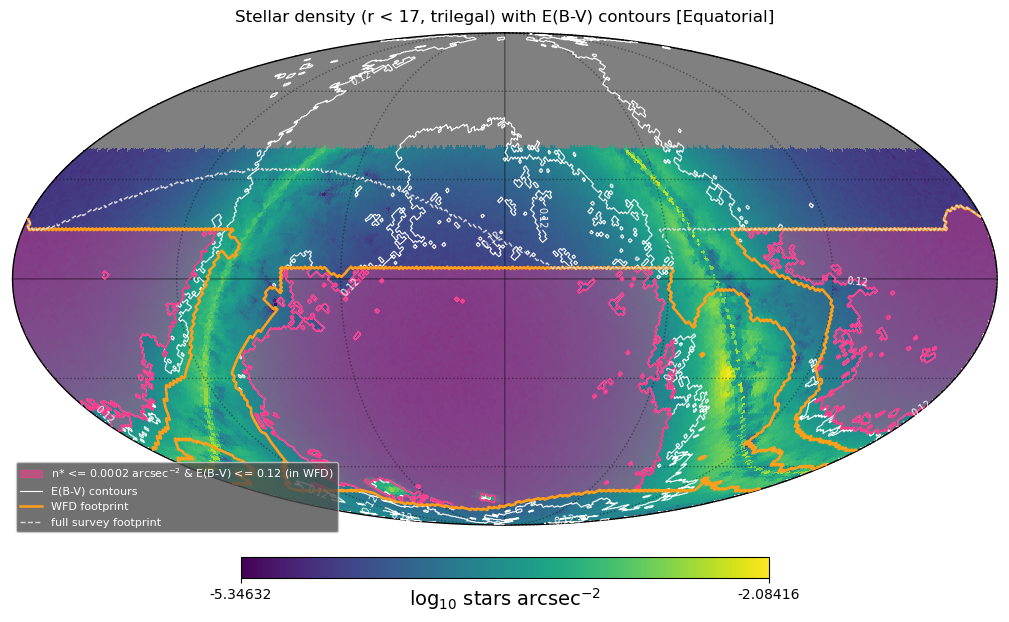

In [9]:
fig = plt.figure(figsize=(11, 6.5))
hp.mollview(
    logdens_p, fig=fig.number, cmap="viridis",
    title=f"Stellar density ({FILTER} < {MAG_LIMIT:g}, {STAR_MODEL}) with E(B-V) contours [{frame}]",
    unit=r"log$_{10}$ stars arcsec$^{-2}$",
)
hp.graticule(dpar=30, dmer=60, alpha=0.4)

# Project E(B-V) onto the same Mollweide grid and contour it on the same axes
proj = hp.projector.MollweideProj(xsize=1600)
img = proj.projmap(ebv_p, lambda x, y, z: hp.vec2pix(NSIDE, x, y, z))
img = np.ma.masked_where(~np.isfinite(img) | (img == hp.UNSEEN), img)
x0, x1, y0, y1 = proj.get_extent()
X, Y = np.meshgrid(np.linspace(x0, x1, img.shape[1]), np.linspace(y0, y1, img.shape[0]))

ax = plt.gca()
cs = ax.contour(X, Y, img, levels=EBV_LEVELS, colors="white", linewidths=0.8)
ax.clabel(cs, fmt="%.2f", fontsize=7)

# Joint-cut layer: translucent fill plus a solid outline
selimg = proj.projmap(sel.astype(float), lambda x, y, z: hp.vec2pix(NSIDE, x, y, z))
selimg = np.ma.masked_where(~np.isfinite(selimg) | (selimg == hp.UNSEEN), selimg)
ax.contourf(X, Y, selimg, levels=[0.5, 1.5], colors=[CUT_COLOR], alpha=0.35)
ax.contour(X, Y, selimg, levels=[0.5], colors=[CUT_COLOR], linewidths=1.2)

# Footprint outlines: WFD solid, full survey footprint dashed
def outline(mask, **kw):
    im = proj.projmap(mask.astype(float), lambda x, y, z: hp.vec2pix(NSIDE, x, y, z))
    im = np.ma.masked_where(~np.isfinite(im) | (im == hp.UNSEEN), im)
    plt.gca().contour(X, Y, im, levels=[0.5], **kw)

outline(wfd_p, colors=[WFD_COLOR], linewidths=1.8)
if SHOW_FULL_FOOTPRINT:
    outline(survey_p, colors=["0.85"], linewidths=1.0, linestyles="--")

handles = [Patch(facecolor=CUT_COLOR, edgecolor=CUT_COLOR, alpha=0.5, label=cut_label),
           Line2D([], [], color="white", lw=0.8, label="E(B-V) contours"),
           Line2D([], [], color=WFD_COLOR, lw=1.8, label="WFD footprint")]
if SHOW_FULL_FOOTPRINT:
    handles.append(Line2D([], [], color="0.85", lw=1.0, ls="--", label="full survey footprint"))
ax.legend(
    handles=handles,
    loc="lower left", bbox_to_anchor=(0.0, -0.02), fontsize=8, framealpha=0.8,
    facecolor="0.3", labelcolor="white",
)

fig.savefig(OUTFILE, dpi=150, bbox_inches="tight")
print("wrote", OUTFILE)
plt.show()

## 9. Galactic-plane input: the TVS SC region

Builds the region that shapes the `rgps` component in section 10, following the TVS SC notebook [`modified_galplane_footprint.ipynb`](https://github.com/LSST-TVSSC/software_tools/blob/main/GalPlaneSurvey/modified_galplane_footprint.ipynb):

1. Rank the scheduler's `bulgy` pixels by the TVS Galactic Plane priority map.
2. Keep the highest-priority pixels until their baseline visits reach (1 − `TVS_REDUCE_FRACTION`) of the current total. Visits are counted with MAF `CountMetric` and `fiveSigmaDepth > 21.5` on the baseline OpSim run. If no OpSim database is found, the cell falls back to equal visits per pixel.
3. Add the Roman RGPS wide-field boxes (`RGPS_BOXES`).
4. Drop pixels at 180° < l < 270° and keep b < 11°. This gives the plane part, `tvs_gp`.
5. Build the TVS ecliptic bridge, `tvs_bridge`: ecliptic longitude 235–305°, latitude ±2.5°. Section 10 hands it to the bridge, not to `rgps`.

In [10]:
npix = hp.nside2npix(NSIDE)
th, ph = hp.pix2ang(NSIDE, np.arange(npix))
_gth, _gph = hp.Rotator(coord=["C", "G"])(th, ph)
gl = (np.degrees(_gph) + 180.0) % 360.0 - 180.0      # Galactic l, b of every (equatorial) pixel
gb = 90.0 - np.degrees(_gth)

# 1. priority map (equatorial, RING, nside 64) over the current bulgy pixels
prio = fits.getdata(TVS_PRIORITY_URL, 1, cache=True)["combined_map"] / 6.0
if prio.size != npix:
    prio = hp.ud_grade(prio, NSIDE)
gp_pix = np.where(np.asarray(fp_labels) == "bulgy")[0]
current_gp_map = np.zeros(npix)
current_gp_map[gp_pix] = prio[gp_pix]

# 2. baseline visits per pixel, then keep pixels by priority within the reduced visit budget
nv = None
if TVS_NVISITS_SOURCE == "opsim":
    try:
        db = TVS_OPSIM_DB
        if db is None:
            from rubin_sim.data import get_baseline
            db = get_baseline()
        b_ = maf.MetricBundle(maf.CountMetric(col="observationStartMJD", metric_name="Nvisits"),
                              maf.HealpixSlicer(nside=NSIDE, use_cache=False, verbose=False),
                              "fiveSigmaDepth > 21.5", run_name="baseline")
        maf.MetricBundleGroup({"nvisits": b_}, db, out_dir="tvs_maf_out", results_db=None).run_all()
        nv = b_.metric_values.filled(0.0)
        nv_src = f"MAF Nvisits on {os.path.basename(db)}"
    except Exception as e:
        print(f"OpSim visits unavailable ({type(e).__name__}: {e}); using uniform visits per pixel")
if nv is None:
    nv = np.ones(npix)
    nv_src = "uniform (1 visit per pixel)"
reduced_nv = (1 - TVS_REDUCE_FRACTION) * nv[gp_pix].sum()
pixel_order = np.argsort(current_gp_map)[::-1]          # same ordering as the TVS notebook
pixel_order = pixel_order[np.isin(pixel_order, gp_pix)]
before = np.concatenate([[0.0], np.cumsum(nv[pixel_order])[:-1]])
reduced = pixel_order[before <= reduced_nv]

# 3. add the Roman wide-field footprint
rgps_core = np.zeros(npix, bool)
for _, ((l0, l1), (b0, b1)) in RGPS_BOXES.items():
    rgps_core |= (gl >= l0) & (gl < l1) & (gb >= b0) & (gb < b1)
tvs_gp = np.zeros(npix, bool)
tvs_gp[reduced] = True
tvs_gp |= rgps_core

# 4. drop the l = 180-270 islands, keep b < TVS_B_MAX
l360 = gl % 360.0
tvs_gp &= ~((l360 > TVS_DROP_L[0]) & (l360 < TVS_DROP_L[1]))
tvs_gp &= gb < TVS_B_MAX

# 5. TVS ecliptic bridge
elon_g, elat_g = np.meshgrid(np.linspace(*TVS_BRIDGE_ELON, 500), np.linspace(*TVS_BRIDGE_ELAT, 100))
ec = SkyCoord(lon=elon_g * u.deg, lat=elat_g * u.deg, frame="barycentricmeanecliptic").icrs
tvs_bridge = np.zeros(npix, bool)
tvs_bridge[hp.ang2pix(NSIDE, ec.ra.deg.ravel(), ec.dec.deg.ravel(), lonlat=True)] = True

print(f"visits: {nv_src}")
print(f"TVS plane region {tvs_gp.sum() * pix_area:,.0f} deg^2; TVS ecliptic bridge {tvs_bridge.sum() * pix_area:,.0f} deg^2")

visits: MAF Nvisits on baseline_v5.0.0_10yrs.db
TVS plane region 1,595 deg^2; TVS ecliptic bridge 440 deg^2


## 10. Modified footprint

Builds the new footprint from the scheduler's current one. Everything is done in equatorial pixels, the footprint's native frame.

1. **Cut `lowdust`:** `lowdust` pixels that pass the joint cut stay `lowdust`. The cut is applied over the whole sky here, without the WFD restriction.
2. **Smooth `lowdust`:** the `lowdust` edge is smoothed (`LOWDUST_SMOOTH_FWHM`). It trades area only with non-WFD regions.
3. **Fill holes:** `lowdust` area lost in steps 1–2 goes to the nearest non-WFD region (`HOLE_FILL_LABELS`).
4. **Galactic plane (`rgps`):** `bulgy` is replaced by the TVS plane region from section 9. All of it at l > `RGPS_NORTH_L_MIN` (the thin northern plane) is dropped. The TVS ecliptic-bridge pixels are left for the bridge, and `RGPS_PROTECT` regions are never taken. Leftover `bulgy` goes to the nearest non-WFD region.
5. **Fill holes:** every gap that `rgps` completely encloses is filled. The exceptions are gaps containing a protected region (`RGPS_PROTECT`), which can't occur here.
6. **Trim and smooth together:** the `rgps` mask is smoothed with a `RGPS_SMOOTH_FWHM` Gaussian and thresholded to keep exactly the target number of pixels: the current area, minus `RGPS_EDGE_TRIM_FRAC` (or down to `RGPS_EDGE_TRIM_TO_AREA`). The trim therefore falls evenly along a smooth edge instead of leaving a ragged one. Trimmed area becomes `dusty_plane` and isn't passed on to the bridge. The border never moves into the TVS bridge reservation or the northern cut.
7. **Clean shape:** pixels hanging on by a corner are shaved, one-pixel notches are filled, only the largest piece is kept, and any holes are filled again. The cell reports the number of pieces and holes left (expect 1 piece, 0 holes) and draws a close-up of the plane.
8. **Ecliptic bridge:** a band centred on the ecliptic where it crosses the plane near the bulge. It always includes the TVS ecliptic-bridge pixels and only takes `dusty_plane`. It stays out of the northern plane and keeps only pieces that touch `rgps`. Its width is solved so its area is `BRIDGE_TARGET_AREA` plus the `rgps` shortfall from `RGPS_TARGET_AREA`, up to `BRIDGE_MAX_WIDTH`. **The cell prints the width** and checks that `rgps` reaches `lowdust` on both sides of the plane.

**Visit budget.** Steps 1–8 are wrapped in `build_footprint(stardens_cut, edge_trim_frac, bridge_target_area)`. If `TARGET_TOTAL_VISITS` is set, the cell first searches for the largest `STARDENS_CUT` that keeps the total under that number (bisection in log, down to `STARDENS_SOLVE_MIN`). It keeps `RGPS_EDGE_TRIM_FRAC` and `BRIDGE_TARGET_AREA` as set. It prints each trial and then builds the footprint with the cut it found. Everything below section 10 uses that cut. Sections 7–8 were drawn with the Settings value, so put the solved cut into Settings and rerun to make them match.

Rule of thumb: every deg² moved from WFD (750 visits) to `dusty_plane` (170) saves (750 − 170) × 1.3 / 9.6 ≈ 79 visits.

1-3. lowdust: 17,566 -> 14,607 deg^2 (2,969 deg^2 to non-WFD regions)
4.   rgps: 1,516 deg^2 from the TVS plane region (l <= 30 deg); TVS bridge 283 deg^2 kept for the bridge; 265 deg^2 of bulgy -> non-WFD
6-7. rgps smoothed (FWHM 4 deg): 1,521 deg^2 in 1 piece; holes filled 5 deg^2, holes left 0 (protected regions only); islands removed 0 deg^2
8.   BRIDGE WIDTH = 13.64 deg (ecliptic latitude -6.82 to +6.82 deg); area 579 deg^2 (target 579: 400 + rgps shortfall)
     rgps reaches lowdust north of the plane: YES, south: YES

STARDENS_CUT = 0.0002, RGPS_EDGE_TRIM_FRAC = 0, BRIDGE_TARGET_AREA = 400: total visits 1,963,041 (current footprint 2,169,385)


/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/healpy/visufunc.py:764: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


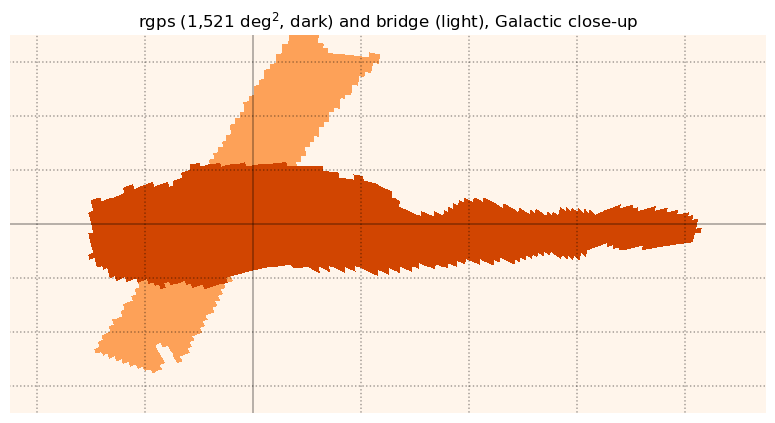

In [11]:
NBRS = hp.get_all_neighbours(NSIDE, np.arange(npix))      # (8, npix), -1 = none


def to_frame_nearest(m, src, dst):
    """Rotate by nearest-pixel lookup (no interpolation): good for masks and labels."""
    if src == dst:
        return m
    th2, ph2 = hp.Rotator(coord=[dst, src])(th, ph)
    return m[hp.ang2pix(NSIDE, th2, ph2)]


def components(mask, edges_only=False):
    """Connected groups of True pixels: returns (pixels, group id per pixel). Neighbours are
    the 8 surrounding pixels, or only the 4 sharing an edge (SW, NW, NE, SE) if edges_only."""
    pix = np.where(mask)[0]
    idx = -np.ones(npix, dtype=int)
    idx[pix] = np.arange(pix.size)
    nb = NBRS[[0, 2, 4, 6]][:, pix] if edges_only else NBRS[:, pix]
    ok = (nb >= 0) & mask[np.clip(nb, 0, None)]
    r = np.broadcast_to(np.arange(pix.size), nb.shape)[ok]
    adj = coo_matrix((np.ones(r.size), (r, idx[nb[ok]])), shape=(pix.size, pix.size))
    return pix, connected_components(adj, directed=False)[1]


def fill_nearest(labels, mask, cand_labels, mode="component"):
    """Relabel the pixels in mask with the nearest region in cand_labels: per connected
    piece (the region it shares most edges with, else the closest) or per pixel."""
    cand = np.isin(labels, cand_labels) & ~mask
    if not mask.any():
        return np.array([], "U20")
    cpix = np.where(cand)[0]
    tree = cKDTree(np.array(hp.pix2vec(NSIDE, cpix)).T)
    if mode == "pixel":
        pix = np.where(mask)[0]
        _, j = tree.query(np.array(hp.pix2vec(NSIDE, pix)).T)
        out = labels[cpix[j]]
    else:
        pix, gid = components(mask)
        out = np.empty(pix.size, dtype="U20")
        for g in np.unique(gid):
            members = pix[gid == g]
            touch = NBRS[:, members].ravel()
            touch = touch[touch >= 0]
            touch = touch[cand[touch]]
            if touch.size:
                labs, cnt = np.unique(labels[touch], return_counts=True)
                out[gid == g] = labs[np.argmax(cnt)]
            else:
                d, j = tree.query(np.array(hp.pix2vec(NSIDE, members)).T)
                out[gid == g] = labels[cpix[j[np.argmin(d)]]]
    labels[pix] = out
    return out


def smoothed_fraction(mask, allowed, fwhm):
    """Normalised convolution: smoothed mask / smoothed allowed area."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        num = hp.smoothing(mask.astype(float), fwhm=np.radians(fwhm))
        den = hp.smoothing(allowed.astype(float), fwhm=np.radians(fwhm))
    return np.where(allowed & (den > 0.05), num / np.maximum(den, 1e-6), -1.0)


def area(mask):
    return mask.sum() * pix_area


def enclosed_holes(region, protect):
    """Pixels outside `region` that it completely encloses: every piece of the complement
    (edge-connected) except the largest one, the open sky. Pieces containing a protected
    pixel are left alone."""
    cpix, cgid = components(~region, edges_only=True)
    sizes = np.bincount(cgid)
    holes_ = np.zeros(npix, bool)
    for g in np.where(np.arange(sizes.size) != np.argmax(sizes))[0]:
        mem = cpix[cgid == g]
        if not protect[mem].any():
            holes_[mem] = True
    return holes_


def build_footprint(stardens_cut, edge_trim_frac, bridge_target_area, verbose=True):
    """Steps 1-8 for one set of the three budget knobs. Returns the new labels and summary values."""
    say = print if verbose else (lambda *a, **k: None)
    old_labels = np.asarray(fp_labels).astype("U20")
    new_labels = old_labels.copy()

    # ---- 1-3. lowdust: joint cut, smoothed edge, holes to the nearest non-WFD region ----
    cut_c = (side_mask(to_frame_nearest(logdens, star_frame, "C"), np.log10(stardens_cut), STARDENS_SIDE)
             & side_mask(to_frame_nearest(ebv, dust_frame, "C"), EBV_CUT, EBV_SIDE))
    is_low = old_labels == "lowdust"
    claim = np.isin(old_labels, CLAIM_FROM_LABELS) & cut_c
    low = (is_low & cut_c) | claim
    if LOWDUST_SMOOTH_FWHM > 0:
        tradeable = np.isin(old_labels, HOLE_FILL_LABELS) | is_low | claim
        low = tradeable & (smoothed_fraction(low, tradeable, LOWDUST_SMOOTH_FWHM) >= 0.5)
    new_labels[low] = "lowdust"
    holes = is_low & ~low
    new_labels[holes] = ""
    fill_nearest(new_labels, holes, HOLE_FILL_LABELS, HOLE_MODE)
    say(f"1-3. lowdust: {area(is_low):,.0f} -> {area(new_labels == 'lowdust'):,.0f} deg^2 "
          f"({area(holes):,.0f} deg^2 to non-WFD regions)")

    # ---- 4. rgps from the TVS plane region; thin northern plane dropped ----
    reserved = tvs_bridge & ~tvs_gp                      # TVS ecliptic bridge: kept for the bridge
    north_cut = gl > RGPS_NORTH_L_MIN
    rgps = tvs_gp & ~np.isin(new_labels, RGPS_PROTECT) & ~reserved & ~north_cut
    n_target = int(round(RGPS_TARGET_AREA / pix_area))
    if rgps.sum() > n_target:                            # over budget: drop farthest from the Galactic centre
        gc_vec = np.array(hp.ang2vec(*hp.Rotator(coord=["G", "C"])(np.pi / 2, 0.0)))
        dist_gc = np.arccos(np.clip(np.array(hp.pix2vec(NSIDE, np.arange(npix))).T @ gc_vec, -1, 1))
        rp = np.where(rgps)[0]
        rgps[rp[np.argsort(-dist_gc[rp], kind="stable")[:rgps.sum() - n_target]]] = False
    new_labels[rgps] = RGPS_LABEL
    left = new_labels == "bulgy"
    new_labels[left] = ""
    fill_nearest(new_labels, left, HOLE_FILL_LABELS, "component")
    say(f"4.   rgps: {area(rgps):,.0f} deg^2 from the TVS plane region (l <= {RGPS_NORTH_L_MIN:g} deg); "
          f"TVS bridge {area(reserved):,.0f} deg^2 kept for the bridge; {area(left):,.0f} deg^2 of bulgy -> non-WFD")

    # ---- 5-6. fill enclosed holes, then trim (optional) and smooth the border together ----
    # The Gaussian-smoothed rgps mask is thresholded to keep exactly the target number of
    # pixels: with no trim the area is unchanged; with a trim the cut falls evenly on the edge,
    # so the trimmed border is as smooth as the untrimmed one.
    protect = np.isin(new_labels, RGPS_PROTECT)
    rg = new_labels == RGPS_LABEL
    holes0 = enclosed_holes(rg, protect)
    rg |= holes0
    n_trim = (max(rg.sum() - int(round(RGPS_EDGE_TRIM_TO_AREA / pix_area)), 0)
              if RGPS_EDGE_TRIM_TO_AREA is not None else int(round(edge_trim_frac * rg.sum())))
    n_keep = rg.sum() - n_trim
    blocked = reserved | north_cut                        # the border never moves into these
    allowed = (rg | np.isin(new_labels, HOLE_FILL_LABELS)) & ~blocked
    if RGPS_SMOOTH_FWHM > 0:
        keep = np.zeros(npix, bool)
        keep[np.argsort(-smoothed_fraction(rg, allowed, RGPS_SMOOTH_FWHM), kind="stable")[:n_keep]] = True
    else:
        rp = np.where(rg)[0]
        d, _ = cKDTree(np.array(hp.pix2vec(NSIDE, np.where(~rg)[0])).T).query(np.array(hp.pix2vec(NSIDE, rp)).T)
        keep = rg.copy()
        keep[rp[np.argsort(d, kind="stable")[:n_trim]]] = False
    edge_trimmed = rg & ~keep                             # leaves rgps -> dusty_plane, not for the bridge
    new_labels[keep] = RGPS_LABEL
    new_labels[edge_trimmed] = "dusty_plane"
    if n_trim:
        say(f"5.   edge trim: {n_trim * pix_area:,.0f} deg^2 off the rgps border -> dusty_plane")

    # ---- 7. clean shape: shave corners, fill notches, one piece, no holes ----
    for _ in range(20):
        rg = new_labels == RGPS_LABEL
        n_rg = np.where(NBRS >= 0, rg[np.clip(NBRS, 0, None)], False).sum(axis=0)
        thin = rg & (n_rg < RGPS_MIN_NEIGHBOURS)
        notch = ~rg & ~blocked & ~protect & (new_labels != "") & (n_rg >= 10 - RGPS_MIN_NEIGHBOURS)
        if not (thin.any() or notch.any()):
            break
        new_labels[notch] = RGPS_LABEL
        new_labels[thin] = "dusty_plane"
    rpix, rgid = components(new_labels == RGPS_LABEL)
    islands = np.zeros(npix, bool)
    islands[rpix[rgid != np.argmax(np.bincount(rgid))]] = True
    new_labels[islands] = "dusty_plane"
    holes1 = enclosed_holes(new_labels == RGPS_LABEL, np.isin(new_labels, RGPS_PROTECT))
    new_labels[holes1] = RGPS_LABEL
    rg = new_labels == RGPS_LABEL
    n_holes = np.unique(components(~rg, edges_only=True)[1]).size - 1
    rgps_area = area(rg)
    say(f"6-7. rgps smoothed (FWHM {RGPS_SMOOTH_FWHM:g} deg): {rgps_area:,.0f} deg^2 in "
        f"{np.unique(components(rg)[1]).size} piece; holes filled {area(holes0 | holes1):,.0f} deg^2, "
        f"holes left {n_holes} (protected regions only); islands removed {area(islands):,.0f} deg^2")

    # ---- 8. ecliptic bridge, width solved for the target area ----
    bridge_target = bridge_target_area + max(RGPS_TARGET_AREA - n_trim * pix_area - rgps_area, 0.0)
    takeable = (np.isin(new_labels, BRIDGE_TAKE_FROM) & ~edge_trimmed
                & ~(north_cut & (np.abs(gb) < BRIDGE_NORTH_PLANE_B)))
    seed = reserved & takeable
    plane_mask = new_labels == RGPS_LABEL
    elat = 90.0 - np.degrees(hp.Rotator(coord=["C", "E"])(th, ph)[0])


    def ecl_bridge(width):
        """Takeable pixels within width/2 of the ecliptic (plus the TVS seed), keeping only the
        connected pieces that touch rgps (this excludes the anticentre crossing)."""
        band = takeable & ((np.abs(elat - BRIDGE_ELAT_OFFSET) <= width / 2) | seed)
        out_ = np.zeros(npix, bool)
        if not band.any():
            return out_
        bp, bg = components(band)
        for g in np.unique(bg):
            mem = bp[bg == g]
            nb = NBRS[:, mem].ravel()
            if plane_mask[nb[nb >= 0]].any():
                out_[mem] = True
        return out_


    lo, hi = 0.0, BRIDGE_MAX_WIDTH
    if area(ecl_bridge(hi)) < bridge_target:
        BRIDGE_WIDTH = hi
        say(f"8.   bridge: at the maximum width ({hi:g} deg) only {area(ecl_bridge(hi)):,.0f} of "
              f"{bridge_target:,.0f} deg^2 is available; raise BRIDGE_MAX_WIDTH or accept the shortfall")
    else:
        for _ in range(20):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if area(ecl_bridge(mid)) < bridge_target else (lo, mid)
        a_lo, a_hi = area(ecl_bridge(lo)), area(ecl_bridge(hi))
        BRIDGE_WIDTH = lo if abs(a_lo - bridge_target) <= abs(a_hi - bridge_target) else hi
    bridge = ecl_bridge(BRIDGE_WIDTH)
    new_labels[bridge] = BRIDGE_LABEL

    # connectivity: does rgps reach lowdust (through the bridge) on each side of the plane?
    j_pix, j_gid = components(np.isin(new_labels, [RGPS_LABEL, "lowdust", BRIDGE_LABEL]))
    gid_of = np.full(npix, -1)
    gid_of[j_pix] = j_gid
    main = np.bincount(gid_of[new_labels == RGPS_LABEL]).argmax()
    nb = NBRS[:, np.where(np.isin(new_labels, [RGPS_LABEL, BRIDGE_LABEL]) & (gid_of == main))[0]].ravel()
    adj_low = np.zeros(npix, bool)
    adj_low[nb[nb >= 0]] = True
    adj_low &= new_labels == "lowdust"
    conn = {s: "YES" if (adj_low & m).any() else "NO" for s, m in [("north", gb > 0), ("south", gb < 0)]}

    say(f"8.   BRIDGE WIDTH = {BRIDGE_WIDTH:.2f} deg (ecliptic latitude {BRIDGE_ELAT_OFFSET - BRIDGE_WIDTH / 2:+.2f} "
          f"to {BRIDGE_ELAT_OFFSET + BRIDGE_WIDTH / 2:+.2f} deg); area {area(bridge):,.0f} deg^2 "
          f"(target {bridge_target:,.0f}: {bridge_target_area:g} + rgps shortfall)")
    say(f"     rgps reaches lowdust north of the plane: {conn['north']}, south: {conn['south']}")
    return dict(old_labels=old_labels, new_labels=new_labels, rgps_area=rgps_area, bridge=bridge,
                width=BRIDGE_WIDTH, bridge_target=bridge_target, edge_trimmed=edge_trimmed, conn=conn)


def total_visits(labels):
    """Pointings x median visits, summed over regions."""
    return sum(area(labels == c) * POINTINGS_PER_DEG2 * VISITS.get(c, 0) for c in set(labels) if c)


# ---- optional: solve STARDENS_CUT so the modified footprint uses TARGET_TOTAL_VISITS ----
if TARGET_TOTAL_VISITS is not None:
    def visits_at(cut):
        return total_visits(build_footprint(cut, RGPS_EDGE_TRIM_FRAC, BRIDGE_TARGET_AREA, verbose=False)["new_labels"])
    hi_c, lo_c = STARDENS_CUT, STARDENS_SOLVE_MIN
    v_hi, v_lo = visits_at(hi_c), visits_at(lo_c)
    print(f"solving STARDENS_CUT for {TARGET_TOTAL_VISITS:,.0f} visits "
          f"(edge trim {RGPS_EDGE_TRIM_FRAC:g}, bridge target {BRIDGE_TARGET_AREA:g} deg^2):")
    print(f"    cut {hi_c:.3g} -> {v_hi:,.0f} visits;  cut {lo_c:.3g} -> {v_lo:,.0f} visits")
    if v_hi <= TARGET_TOTAL_VISITS:
        print("    already at or under the target with the Settings cut; keeping it")
    elif v_lo > TARGET_TOTAL_VISITS:
        STARDENS_CUT = lo_c
        print(f"    even STARDENS_SOLVE_MIN = {lo_c:.3g} stays above the target; using it. "
              "Trim rgps or shrink the bridge more, or lower STARDENS_SOLVE_MIN")
    else:
        for _ in range(STARDENS_SOLVE_ITER):              # bisection in log(cut)
            mid = 10 ** (0.5 * (np.log10(lo_c) + np.log10(hi_c)))
            v = visits_at(mid)
            print(f"    cut {mid:.4g} -> {v:,.0f} visits")
            lo_c, hi_c = (mid, hi_c) if v <= TARGET_TOTAL_VISITS else (lo_c, mid)
        STARDENS_CUT = lo_c                                 # largest cut that stays within the target
        print(f"    -> STARDENS_CUT = {STARDENS_CUT:.4g} stars/arcsec^2")
    print()

res = build_footprint(STARDENS_CUT, RGPS_EDGE_TRIM_FRAC, BRIDGE_TARGET_AREA)
old_labels, new_labels, rgps_area, bridge = res["old_labels"], res["new_labels"], res["rgps_area"], res["bridge"]
BRIDGE_WIDTH, bridge_target, edge_trimmed = res["width"], res["bridge_target"], res["edge_trimmed"]
print(f"\nSTARDENS_CUT = {STARDENS_CUT:.4g}, RGPS_EDGE_TRIM_FRAC = {RGPS_EDGE_TRIM_FRAC:g}, "
      f"BRIDGE_TARGET_AREA = {BRIDGE_TARGET_AREA:g}: total visits {total_visits(new_labels):,.0f} "
      f"(current footprint {total_visits(old_labels):,.0f})")

# close-up of the final rgps region in Galactic coordinates (check: smooth edge, no holes)
figz = plt.figure(figsize=(13, 4.2))
hp.cartview(np.where(new_labels == RGPS_LABEL, 1.0, np.where(new_labels == BRIDGE_LABEL, 0.55, 0.0)),
            fig=figz.number, coord=["C", "G"], lonra=[-95, 45], latra=[-35, 35], cmap="Oranges",
            min=0, max=1.3, cbar=False, notext=True,
            title=f"rgps ({rgps_area:,.0f} deg$^2$, dark) and bridge (light), Galactic close-up")
hp.graticule(dpar=10, dmer=20, alpha=0.4)
plt.show()

### 10a. Area and pointings per component

Area and pointings per component, at `POINTINGS_PER_DEG2` (1.3 pointings per 9.6 deg²), for the current and the modified footprint.

In [12]:
NEW_WFD = WFD_LABELS + [RGPS_LABEL, BRIDGE_LABEL]
comps = [l for l in ["lowdust", "euclid_overlap", "virgo", "LMC_SMC", "bulgy", RGPS_LABEL, BRIDGE_LABEL,
                     "dusty_plane", "nes", "scp"]
         if l in set(old_labels) | set(new_labels)]
comps += sorted((set(old_labels) | set(new_labels)) - set(comps) - {""})
rows = []
for c in comps:
    a_old, a_new = area(old_labels == c), area(new_labels == c)
    rows.append({"component": c, "WFD": c in NEW_WFD,
                 "area_current_deg2": a_old, "area_new_deg2": a_new, "change_deg2": a_new - a_old,
                 "pointings_current": a_old * POINTINGS_PER_DEG2,
                 "pointings_new": a_new * POINTINGS_PER_DEG2})
base = pd.DataFrame(rows)
num = base.drop(columns=["component", "WFD"])
tab = pd.concat([base, pd.DataFrame([
    {"component": "WFD total", "WFD": True, **num[base.WFD].sum().to_dict()},
    {"component": "non-WFD total", "WFD": False, **num[~base.WFD].sum().to_dict()},
    {"component": "footprint total", "WFD": None, **num.sum().to_dict()},
])], ignore_index=True)

tab.to_csv(TABLE_STEM + "_areas.csv", index=False)
print(f"bridge width {BRIDGE_WIDTH:.2f} deg")
display(tab.style.format({c: "{:,.0f}" for c in tab.columns if c not in ("component", "WFD")})
        .hide(axis="index"))

bridge width 13.64 deg


component,WFD,area_current_deg2,area_new_deg2,change_deg2,pointings_current,pointings_new
lowdust,True,"17,566","14,607","-2,959","2,379","1,978"
euclid_overlap,True,94,94,0,13,13
virgo,True,83,83,0,11,11
LMC_SMC,True,353,353,0,48,48
bulgy,True,"1,766",0,"-1,766",239,0
rgps,True,0,"1,521","1,521",0,206
bridge,True,0,579,579,0,78
dusty_plane,False,"3,371","5,916","2,546",456,801
nes,False,"3,135","3,214",79,424,435
scp,False,811,811,0,110,110


### 10b. Visit budget

Total visits per component = pointings × median visits per pointing (`VISITS`), for the current and the modified footprint. For scale, `rubin_scheduler` budgets about 2.2 million visits for a 10-year survey.

In [13]:
vt = base[["component", "WFD", "pointings_current", "pointings_new"]].copy()
vt["median_visits"] = vt.component.map(VISITS)
missing = vt.loc[vt.median_visits.isna(), "component"].tolist()
if missing:
    print("no visit count set for:", missing, "(counted as 0)")
vt["median_visits"] = vt.median_visits.fillna(0)
vt["visits_current"] = vt.pointings_current * vt.median_visits
vt["visits_new"] = vt.pointings_new * vt.median_visits
vt["change"] = vt.visits_new - vt.visits_current
cols = ["pointings_current", "pointings_new", "visits_current", "visits_new", "change"]
vt = pd.concat([vt, pd.DataFrame([
    {"component": "WFD total", "WFD": True, **vt.loc[vt.WFD, cols].sum().to_dict()},
    {"component": "non-WFD total", "WFD": False, **vt.loc[~vt.WFD, cols].sum().to_dict()},
    {"component": "TOTAL", "WFD": None, **vt[cols].sum().to_dict()},
])], ignore_index=True)

vt.to_csv(TABLE_STEM + "_visits.csv", index=False)
display(vt.style.format({c: "{:,.0f}" for c in cols + ["median_visits"]}, na_rep="")
        .hide(axis="index"))
tot = vt.iloc[-1]
print(f"total visits: current footprint {tot.visits_current:,.0f}, modified footprint {tot.visits_new:,.0f} "
      f"({tot.change:+,.0f})")

component,WFD,pointings_current,pointings_new,median_visits,visits_current,visits_new,change
lowdust,True,"2,379","1,978",750,"1,784,004","1,483,530","-300,474"
euclid_overlap,True,13,13,750,"9,547","9,547",0
virgo,True,11,11,750,"8,439","8,439",0
LMC_SMC,True,48,48,750,"35,801","35,801",0
bulgy,True,239,0,750,"179,347",0,"-179,347"
rgps,True,0,206,750,0,"154,456","154,456"
bridge,True,0,78,750,0,"58,816","58,816"
dusty_plane,False,456,801,170,"77,594","136,195","58,601"
nes,False,424,435,150,"63,675","65,277","1,603"
scp,False,110,110,100,"10,979","10,979",0


total visits: current footprint 2,169,385, modified footprint 1,963,041 (-206,344)


### 10c. Map of the modified footprint

Shows each component with its area, the bridge width, the current `lowdust` edge (dotted), the Roman wide-field footprint, the DECaPS2 footprint and the ecliptic.

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/healpy/visufunc.py:200: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


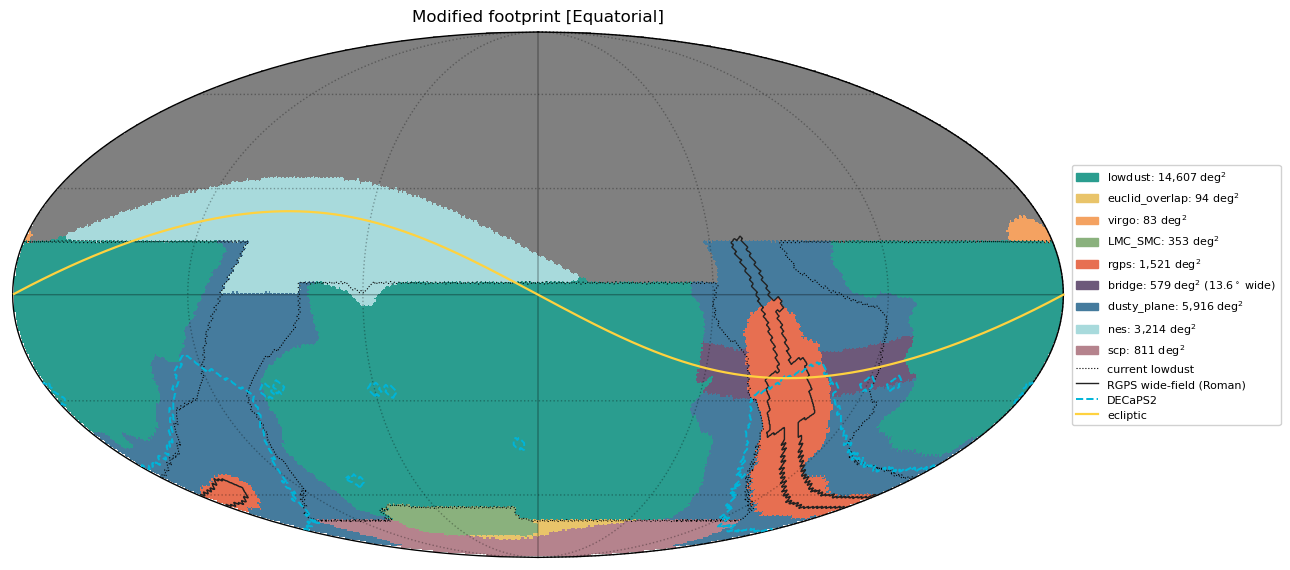

In [14]:
def moc_to_mask(path_or_url, nside):
    """Rasterise a MOC FITS (NUNIQ column) onto a RING map at nside (any-overlap)."""
    with fits.open(path_or_url, cache=True) as f:
        uniq = np.asarray(f[1].data.field(0), dtype=np.int64)
    order_ = (np.floor(np.log2(uniq // 4) / 2)).astype(int)
    ipix = uniq - 4 * 4 ** order_.astype(np.int64)
    o_out = int(np.log2(nside))
    hi_ = order_ >= o_out
    nest = [ipix[hi_] >> (2 * (order_[hi_] - o_out))]          # finer cells -> parent
    for o in np.unique(order_[~hi_]):                           # coarser cells -> children
        k = 4 ** (o_out - o)
        nest.append((ipix[order_ == o][:, None] * k + np.arange(k)[None, :]).ravel())
    m = np.zeros(hp.nside2npix(nside), bool)
    m[hp.nest2ring(nside, np.unique(np.concatenate(nest)))] = True
    return m


order = [c for c in comps if (new_labels == c).any()]
code = np.full(npix, hp.UNSEEN)
for i, c in enumerate(order):
    code[new_labels == c] = i
palette = ["#2a9d8f", "#e9c46a", "#f4a261", "#8ab17d", "#e76f51",
           "#6d597a", "#457b9d", "#a8dadc", "#b5838d", "#ffb4a2"]
colors = (palette * 2)[:len(order)]

fig4 = plt.figure(figsize=(11, 6.5))
hp.mollview(to_frame_nearest(code, "C", target), fig=fig4.number, cmap=ListedColormap(colors),
            min=-0.5, max=len(order) - 0.5, cbar=False,
            title=f"Modified footprint [{frame}]")
hp.graticule(dpar=30, dmer=60, alpha=0.3)


def lbl(c):
    s = f"{c}: {area(new_labels == c):,.0f} deg$^2$"
    return s + (f" ({BRIDGE_WIDTH:.1f}$^\\circ$ wide)" if c == BRIDGE_LABEL else "")


handles = [Patch(color=col, label=lbl(c)) for c, col in zip(order, colors)]

outline(to_frame_nearest(old_labels == "lowdust", "C", target), colors=["k"], linewidths=0.8, linestyles=":")
handles.append(Line2D([], [], color="k", ls=":", lw=0.8, label="current lowdust"))
outline(to_frame_nearest(rgps_core, "C", target), colors=[RGPS_CORE_COLOR], linewidths=1.0)
handles.append(Line2D([], [], color=RGPS_CORE_COLOR, lw=1.0, label="RGPS wide-field (Roman)"))

if SHOW_DECAPS:
    decaps = None
    if DECAPS_SOURCE == "moc":
        try:
            decaps = moc_to_mask(DECAPS_MOC_URL, NSIDE)
        except Exception as e:
            print(f"DECaPS MOC not available ({type(e).__name__}); using the published box")
    if decaps is None:
        (dl0, dl1), (db0, db1) = DECAPS_BOX
        decaps = (gl >= dl0) & (gl <= dl1) & (gb >= db0) & (gb <= db1)
    outline(to_frame_nearest(decaps, "C", target), colors=[DECAPS_COLOR], linewidths=1.4, linestyles="--")
    handles.append(Line2D([], [], color=DECAPS_COLOR, lw=1.4, ls="--", label="DECaPS2"))

elon = np.linspace(0.0, 360.0, 721)
for elat_ in ECLIPTIC_LATS:
    eth, eph = np.radians(90.0 - elat_) * np.ones_like(elon), np.radians(elon)
    if target != "E":
        eth, eph = hp.Rotator(coord=["E", target])(eth, eph)
    hp.projplot(eth, eph, color=ECLIPTIC_COLOR, lw=1.6 if elat_ == 0 else 1.0, ls="-" if elat_ == 0 else "--")
handles.append(Line2D([], [], color=ECLIPTIC_COLOR, lw=1.6, label="ecliptic"))
if any(l != 0 for l in ECLIPTIC_LATS):
    handles.append(Line2D([], [], color=ECLIPTIC_COLOR, lw=1.0, ls="--",
                          label="ecliptic lat " + ", ".join(f"{l:+g}" for l in ECLIPTIC_LATS if l != 0) + " deg"))

plt.gca().legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, framealpha=0.9)
fig4.savefig(TABLE_STEM + ".png", dpi=150, bbox_inches="tight")
plt.show()

### 10d. Export the modified footprint as HEALPix maps

Writes the modified footprint at `OUT_NSIDE`, in equatorial coordinates and RING order:

- **`footprint_GPmod_nside{N}.fits`:** a multi-column HEALPix FITS file with these columns:
  - `label`: integer region code, −1 outside the footprint; the key is in the header as `LABEL0`, `LABEL1`, …
  - `wfd`: 1 for WFD regions, 0 otherwise.
  - `median_visits`: from `VISITS`.
  - `u`…`y`: the scheduler's per-band target weights.

  The header also records the settings, including the bridge width (`BRWIDTH`).
- **`footprint_GPmod_nside{N}.npz`:** the same layout `get_current_footprint()` returns, a structured `footprints` array plus `labels`.

`rgps` and `bridge` borrow their band ratios from existing regions (`BORROW_RATIOS`). Changing `OUT_NSIDE` uses nearest-pixel lookup, so labels are never blended.

                    u      g     r      i      z      y
lowdust         0.350  0.400  1.00  1.000  0.900  0.900
euclid_overlap  0.350  0.400  1.00  1.000  0.900  0.900
virgo           0.350  0.400  1.00  1.000  0.900  0.900
LMC_SMC         0.650  0.650  1.10  1.100  0.340  0.350
rgps            0.170  0.930  0.98  0.980  0.930  0.210
bridge          0.350  0.400  1.00  1.000  0.900  0.900
dusty_plane     0.093  0.260  0.26  0.260  0.260  0.093
nes             0.000  0.255  0.33  0.330  0.230  0.000
scp             0.100  0.175  0.10  0.135  0.046  0.047
wrote footprint_GPmod_nside64.fits (label, wfd, median_visits, u, g, r, i, z, y) and footprint_GPmod_nside64.npz
nside 64: footprint 27,177 deg^2, WFD 17,237 deg^2; bridge width 13.64 deg


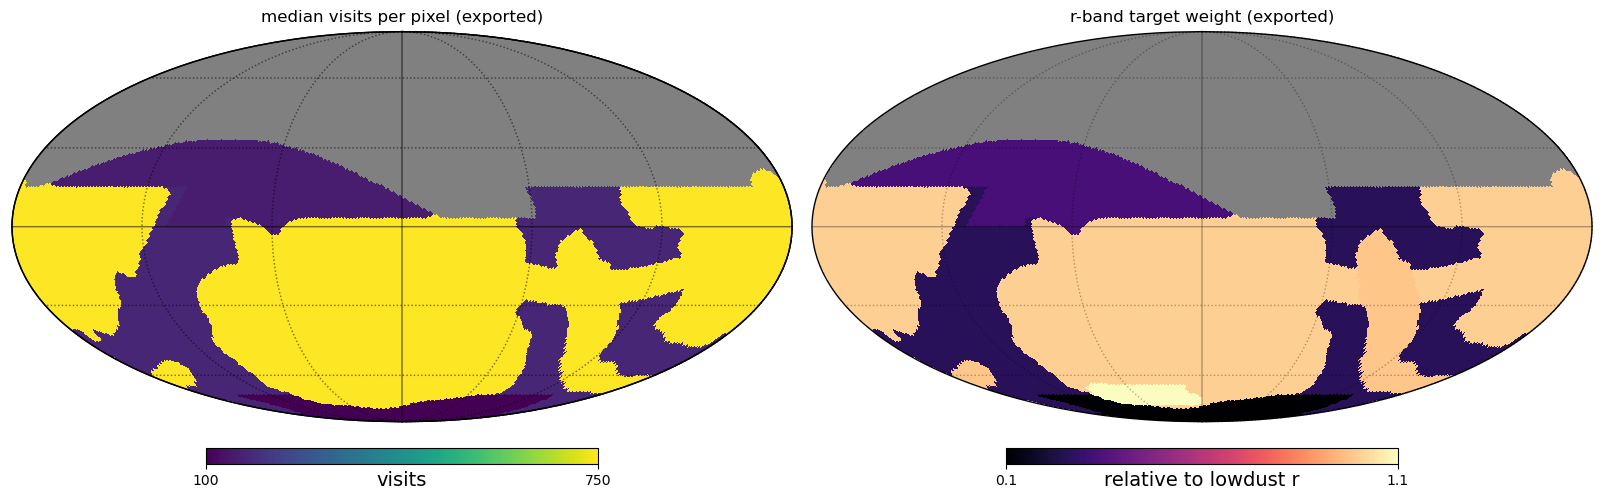

In [15]:
# Per-band ratios for each region, read from the current scheduler footprint
fp_maps, fp_lab = get_current_footprint(nside=NSIDE)
ratios = {lab: {b: float(np.median(fp_maps[b][fp_lab == lab])) for b in BANDS}
          for lab in np.unique(fp_lab[fp_lab != ""])}
for new, src in BORROW_RATIOS.items():
    ratios[new] = ratios[src]
missing = sorted(set(order) - set(ratios))
if missing:
    raise ValueError(f"no band ratios for {missing}; add them to BORROW_RATIOS")
print(pd.DataFrame(ratios).T.loc[order].round(3).to_string())

# Resample the label map to OUT_NSIDE by nearest pixel
if OUT_NSIDE == NSIDE:
    out_labels = new_labels
else:
    th_o, ph_o = hp.pix2ang(OUT_NSIDE, np.arange(hp.nside2npix(OUT_NSIDE)))
    out_labels = new_labels[hp.ang2pix(NSIDE, th_o, ph_o)]

code_of = {c: i for i, c in enumerate(order)}
label_col = np.array([code_of.get(l, -1) for l in out_labels], dtype=np.int32)
wfd_col = np.isin(out_labels, NEW_WFD).astype(np.int16)
visits_col = np.array([VISITS.get(l, 0) if l else 0 for l in out_labels], dtype=np.float32)
footprints = np.zeros(out_labels.size, dtype=list(zip(BANDS, [float] * len(BANDS))))
for l in order:
    m = out_labels == l
    for b in BANDS:
        footprints[b][m] = ratios[l][b]

# 1) multi-column HEALPix FITS
cols = [label_col, wfd_col, visits_col] + [footprints[b].astype(np.float32) for b in BANDS]
names = ["label", "wfd", "median_visits"] + BANDS
hdr = [(f"LABEL{i}", c) for i, c in enumerate(order)] + [
    ("STARMOD", STAR_MODEL), ("FILTER", FILTER), ("MAGLIM", MAG_LIMIT),
    ("SDCUT", STARDENS_CUT), ("SDSIDE", STARDENS_SIDE), ("EBVCUT", EBV_CUT), ("EBVSIDE", EBV_SIDE),
    ("RGPSAREA", float(rgps_area)), ("RGPSLMAX", RGPS_NORTH_L_MIN),
    ("BRAREA", float(area(bridge))), ("BRWIDTH", round(float(BRIDGE_WIDTH), 3)),
]
hp.write_map(OUT_STEM + ".fits", cols, coord="C", column_names=names,
             dtype=[np.int32, np.int16, np.float32] + [np.float32] * len(BANDS),
             extra_header=hdr, overwrite=True)

# 2) scheduler-style npz: same layout as get_current_footprint()
np.savez(OUT_STEM + ".npz", footprints=footprints, labels=out_labels.astype("U20"))

chk = hp.read_map(OUT_STEM + ".fits", field=None)
pa_out = hp.nside2pixarea(OUT_NSIDE, degrees=True)
print(f"wrote {OUT_STEM}.fits ({', '.join(names)}) and {OUT_STEM}.npz")
print(f"nside {OUT_NSIDE}: footprint {(chk[0] >= 0).sum() * pa_out:,.0f} deg^2, "
      f"WFD {(chk[1] == 1).sum() * pa_out:,.0f} deg^2; bridge width {BRIDGE_WIDTH:.2f} deg")

fig5 = plt.figure(figsize=(16, 5))
hp.mollview(np.where(label_col >= 0, visits_col, hp.UNSEEN), fig=fig5.number, sub=(1, 2, 1),
            cmap="viridis", title="median visits per pixel (exported)", unit="visits")
hp.graticule(dpar=30, dmer=60, alpha=0.3)
hp.mollview(np.where(label_col >= 0, footprints["r"], hp.UNSEEN), fig=fig5.number, sub=(1, 2, 2),
            cmap="magma", title="r-band target weight (exported)", unit="relative to lowdust r")
hp.graticule(dpar=30, dmer=60, alpha=0.3)
plt.show()